# Étape 8 — Phase C : modèles SOTA fondationnels (MAE / DINOv2 / FaceNet)


**Plan Phase C** — 3 nouveaux modèles SOTA :

D7 = MAE-ViT-B - ImageNet via reconstruction (Masked Autoencoder)   
D8 = DINOv2 ViT-B - LVD-142M (142M images) self-supervised   
D9 = FaceNet (IResNet1) - VGGFace2 (3.3M visages) |  

Modèles retenus de la Phase B+ : F1, F2, M3, S5 (drop M4, S6).

## 1. Setup

In [1]:
import sys, time, pickle
from pathlib import Path

ROOT = Path.cwd()   # racine du depot (les notebooks sont a la racine)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from dc_utils.paths import IMAGE_DIR, ARTIFACTS_DIR
from dc_utils.training import TrainConfig, train_model, OcclusionDataset, default_eval_tf
from dc_utils.metric import compute_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device =', device, '| torch', torch.__version__, '| timm', timm.__version__)

EXP_DIR = ROOT / 'experiments'
df_train = pd.read_csv(ROOT / 'data' / 'train_split.csv')
df_val   = pd.read_csv(ROOT / 'data' / 'val_split.csv')
print('train:', len(df_train), '| val:', len(df_val))

class TimmRegressor(nn.Module):
    def __init__(self, backbone_name: str, pretrained: bool = True, bias_init: float | None = None,
                 model_kwargs: dict | None = None):
        super().__init__()
        kw = model_kwargs or {}
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=1, **kw)
        if bias_init is not None:
            head = self.backbone.get_classifier()
            with torch.no_grad():
                head.bias.fill_(bias_init); head.weight.mul_(0.01)
    def forward(self, x):
        return torch.sigmoid(self.backbone(x)).squeeze(-1)

_p0 = float(df_train['FaceOcclusion'].mean())
HEAD_BIAS_INIT = float(np.log(_p0 / (1.0 - _p0)))
print(f'mean target = {_p0:.4f} | bias_init = {HEAD_BIAS_INIT:.4f}')

RESULTS: list[dict] = []
def log_run(name, history, best, notes=''):
    history.to_csv(EXP_DIR / f'history_{name}.csv', index=False)
    RESULTS.append({'name': name, 'best_epoch': best['epoch'], 'val_score': best['score'],
                    'err_F': best['err_F'], 'err_M': best['err_M'], 'gap': best['gap'], 'notes': notes})
    print(f'\n>>> {name}: val_score = {best["score"]:.5f} (epoch {best["epoch"]})\n')

<repo>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device = cuda | torch 2.2.2+cu121 | timm 1.0.27
train: 89793 | val: 9977
mean target = 0.0827 | bias_init = -2.4069


## 2. D7 — MAE ViT-Base avec freeze des 8 premiers blocks

**Pourquoi freeze 8/12 blocks** :
- les early blocks MAE = features bas niveau (textures, bords) → universelles
- les late blocks = high-level (objets) → c'est là qu'on doit adapter au domaine occlusion
- moins de params trainable (~22M sur 86M) → moins d'overfitting + plus rapide

In [3]:
def make_mae_partial_freeze(n_unfrozen_blocks: int = 4, seed: int = 42):
    torch.manual_seed(seed); np.random.seed(seed)
    m = TimmRegressor('vit_base_patch16_224.mae', bias_init=HEAD_BIAS_INIT).to(device)
    bb = m.backbone
    # Freeze patch embedding + pos embed + cls_token + early blocks
    for p in bb.patch_embed.parameters(): p.requires_grad = False
    if hasattr(bb, 'cls_token') and bb.cls_token is not None:
        bb.cls_token.requires_grad = False
    if hasattr(bb, 'pos_embed') and bb.pos_embed is not None:
        bb.pos_embed.requires_grad = False
    # Freeze les (12 - n) premiers blocks
    n_freeze = len(bb.blocks) - n_unfrozen_blocks
    for blk in bb.blocks[:n_freeze]:
        for p in blk.parameters(): p.requires_grad = False
    n_train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in m.parameters())
    print(f'MAE-ViT-B (freeze {n_freeze}/{len(bb.blocks)} blocks): '
          f'{n_train/1e6:.2f}M / {n_total/1e6:.2f}M trainable')
    return m

model = make_mae_partial_freeze(n_unfrozen_blocks=4, seed=42)
cfg = TrainConfig(epochs=8, lr=2e-4, weight_decay=5e-4, batch_size=64, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_D7_mae_vit_b.pt', log_prefix='[D7] ',
)
log_run('D7_mae_vit_b', hist, best, notes='vit_base_patch16_224.mae freeze 8/12 blocks, lr=2e-4, 8ep, BS=64')

MAE-ViT-B (freeze 8/12 blocks): 28.35M / 85.80M trainable


decode 99770 imgs: 100%|██████████| 99770/99770 [03:43<00:00, 446.91it/s]


  -> RAM cache: shape (99770, 224, 224, 3) | dtype uint8 | 15.02 GB (single ndarray, fork-safe)


[D7] ep 1 | loss 0.00199 | score 0.00151 | err_F 0.00090 | err_M 0.00130 | gap 0.00040 | 140s *


[D7] ep 2 | loss 0.00124 | score 0.00155 | err_F 0.00096 | err_M 0.00136 | gap 0.00040 | 135s


...

[D7] ep 4 | loss 0.00071 | score 0.00167 | err_F 0.00081 | err_M 0.00138 | gap 0.00057 | 135s


[D7] ep 5 | loss 0.00055 | score 0.00151 | err_F 0.00080 | err_M 0.00127 | gap 0.00047 | 135s


[D7] ep 6 | loss 0.00042 | score 0.00135 | err_F 0.00067 | err_M 0.00112 | gap 0.00046 | 135s *


[D7] ep 7 | loss 0.00034 | score 0.00127 | err_F 0.00062 | err_M 0.00106 | gap 0.00044 | 135s *


[D7] ep 8 | loss 0.00027 | score 0.00126 | err_F 0.00061 | err_M 0.00104 | gap 0.00044 | 135s *

>>> D7_mae_vit_b: val_score = 0.00126 (epoch 8)



## 3. D8 — DINOv2 ViT-Base (full fine-tune)

In [4]:
torch.manual_seed(42); np.random.seed(42)
model = TimmRegressor('vit_base_patch14_dinov2.lvd142m',
                     bias_init=HEAD_BIAS_INIT,
                     model_kwargs={'img_size': 224}).to(device)
n = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'DINOv2 ViT-B/14 @224: {n/1e6:.2f}M params (full FT)')

cfg = TrainConfig(epochs=17, lr=3e-5, weight_decay=1e-4, batch_size=48, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_D8_dinov2_vit_b.pt', log_prefix='[D8] ',
)
log_run('D8_dinov2_vit_b', hist, best, notes='vit_base_patch14_dinov2.lvd142m @224, lr=3e-5, 17ep, BS=48')

DINOv2 ViT-B/14 @224: 85.73M params (full FT)


[D8] ep 1 | loss 0.00310 | score 0.00255 | err_F 0.00167 | err_M 0.00225 | gap 0.00059 | 348s *


[D8] ep 2 | loss 0.00198 | score 0.00192 | err_F 0.00111 | err_M 0.00165 | gap 0.00054 | 347s *


[D8] ep 3 | loss 0.00171 | score 0.00181 | err_F 0.00117 | err_M 0.00159 | gap 0.00043 | 347s *


[D8] ep 4 | loss 0.00141 | score 0.00172 | err_F 0.00104 | err_M 0.00150 | gap 0.00045 | 346s *


...

[D8] ep13 | loss 0.00034 | score 0.00141 | err_F 0.00060 | err_M 0.00114 | gap 0.00054 | 347s


[D8] ep14 | loss 0.00029 | score 0.00128 | err_F 0.00052 | err_M 0.00103 | gap 0.00050 | 347s *


[D8] ep15 | loss 0.00024 | score 0.00123 | err_F 0.00048 | err_M 0.00098 | gap 0.00050 | 347s *


[D8] ep16 | loss 0.00021 | score 0.00126 | err_F 0.00048 | err_M 0.00100 | gap 0.00051 | 347s


[D8] ep17 | loss 0.00019 | score 0.00122 | err_F 0.00048 | err_M 0.00097 | gap 0.00050 | 347s *

>>> D8_dinov2_vit_b: val_score = 0.00122 (epoch 17)



## 4. D9 — FaceNet (InceptionResnetV1 pré-entraîné VGGFace2)

pré-entraîné sur **3.3M images de visages** (VGGFace2)

In [ ]:
from facenet_pytorch import InceptionResnetV1

class FaceNetRegressor(nn.Module):
    """Wrapper FaceNet : prend du (B,3,224,224) normalisé ImageNet,
    dénormalize → resize 160 → normalize [-1,1] FaceNet → embed → head."""
    
    _IM_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    _IM_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    def __init__(self, pretrained: str = 'vggface2', bias_init: float | None = None):
        super().__init__()
        self.backbone = InceptionResnetV1(pretrained=pretrained)
        # Embedding 512-dim 
        self.head = nn.Linear(512, 1)
        if bias_init is not None:
            with torch.no_grad():
                self.head.bias.fill_(bias_init); self.head.weight.mul_(0.01)
        
        self.register_buffer('im_mean', self._IM_MEAN.clone())
        self.register_buffer('im_std',  self._IM_STD.clone())

    def get_classifier(self):
        return self.head

    def forward(self, x):
        
        x = x * self.im_std + self.im_mean              
        x = F.interpolate(x, size=(160, 160), mode='bilinear', align_corners=False)
        x = (x - 0.5) / 0.5                              
        emb = self.backbone(x)                           
        return torch.sigmoid(self.head(emb)).squeeze(-1)

torch.manual_seed(42); np.random.seed(42)
model = FaceNetRegressor(pretrained='vggface2', bias_init=HEAD_BIAS_INIT).to(device)
n = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'FaceNet IResNet1 vggface2 + head: {n/1e6:.2f}M params')

cfg = TrainConfig(epochs=10, lr=1e-4, weight_decay=1e-4, batch_size=128, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_D9_facenet.pt', log_prefix='[D9] ',
)
log_run('D9_facenet', hist, best, notes='InceptionResnetV1 vggface2 + Linear(512,1), lr=1e-4, 10ep, BS=128')

FaceNet IResNet1 vggface2 + head: 27.91M params


[D9] ep 1 | loss 0.00741 | score 0.00277 | err_F 0.00252 | err_M 0.00202 | gap 0.00050 | 95s *


[D9] ep 2 | loss 0.00184 | score 0.00178 | err_F 0.00113 | err_M 0.00156 | gap 0.00043 | 93s *


[D9] ep 3 | loss 0.00134 | score 0.00163 | err_F 0.00099 | err_M 0.00142 | gap 0.00043 | 92s *


[D9] ep 4 | loss 0.00110 | score 0.00142 | err_F 0.00065 | err_M 0.00116 | gap 0.00051 | 91s *


...

[D9] ep 6 | loss 0.00075 | score 0.00135 | err_F 0.00058 | err_M 0.00109 | gap 0.00052 | 93s


[D9] ep 7 | loss 0.00064 | score 0.00134 | err_F 0.00055 | err_M 0.00108 | gap 0.00052 | 89s


[D9] ep 8 | loss 0.00054 | score 0.00133 | err_F 0.00054 | err_M 0.00107 | gap 0.00053 | 88s *


[D9] ep 9 | loss 0.00049 | score 0.00123 | err_F 0.00051 | err_M 0.00099 | gap 0.00048 | 88s *


[D9] ep10 | loss 0.00045 | score 0.00124 | err_F 0.00051 | err_M 0.00099 | gap 0.00049 | 88s

>>> D9_facenet: val_score = 0.00123 (epoch 9)



## 5. Reload des 7 modèles utiles (drop M4, S6)

In [ ]:
def load_timm_ckpt(backbone_name: str, ckpt_path: Path, model_kwargs: dict | None = None) -> nn.Module:
    m = TimmRegressor(backbone_name, pretrained=False, model_kwargs=model_kwargs).to(device)
    state = torch.load(ckpt_path, map_location=device, weights_only=False)
    m.load_state_dict(state['model'])
    m.eval()
    print(f'loaded {ckpt_path.name} | best ep={state.get("epoch")} | val={state.get("val", {}).get("score", "?"):.5f}'
          if isinstance(state.get('val'), dict) else f'loaded {ckpt_path.name}')
    return m

def load_facenet_ckpt(ckpt_path: Path) -> nn.Module:
    m = FaceNetRegressor(pretrained=None).to(device)
    state = torch.load(ckpt_path, map_location=device, weights_only=False)
    
    sd = state['model']
    missing, unexpected = m.load_state_dict(sd, strict=False)
    
    bad = [k for k in unexpected if not k.startswith('backbone.logits.')]
    assert not missing, f'Missing keys: {missing}'
    assert not bad, f'Unexpected keys (autres que logits): {bad}'
    m.eval()
    val = state.get('val', {})
    print(f'loaded {ckpt_path.name} (FaceNet) | best ep={state.get("epoch")} | val={val.get("score","?"):.5f}'
          if isinstance(val, dict) and 'score' in val else f'loaded {ckpt_path.name} (FaceNet)')
    return m

models = {
    'F1_effb0':           load_timm_ckpt('efficientnet_b0',                ARTIFACTS_DIR / 'exp_F1_effb0.pt'),
    'F2_convnext':        load_timm_ckpt('convnext_tiny',                  ARTIFACTS_DIR / 'exp_F2_convnext.pt'),
    'M3_convnext_seed1':  load_timm_ckpt('convnext_tiny',                  ARTIFACTS_DIR / 'exp_M3_convnext_seed1.pt'),
    'S5_swin_tiny':       load_timm_ckpt('swin_tiny_patch4_window7_224',   ARTIFACTS_DIR / 'exp_S5_swin_tiny.pt'),
    'D7_mae_vit_b':       load_timm_ckpt('vit_base_patch16_224.mae',       ARTIFACTS_DIR / 'exp_D7_mae_vit_b.pt'),
    'D8_dinov2_vit_b':    load_timm_ckpt('vit_base_patch14_dinov2.lvd142m',ARTIFACTS_DIR / 'exp_D8_dinov2_vit_b.pt',
                                          model_kwargs={'img_size': 224}),
    'D9_facenet':         load_facenet_ckpt(ARTIFACTS_DIR / 'exp_D9_facenet.pt'),
}
print(f'\n{len(models)} modèles chargés')

loaded exp_F1_effb0.pt | best ep=7 | val=0.00120
loaded exp_F2_convnext.pt | best ep=7 | val=0.00116
loaded exp_M3_convnext_seed1.pt | best ep=6 | val=0.00116
loaded exp_S5_swin_tiny.pt | best ep=6 | val=0.00110
loaded exp_D7_mae_vit_b.pt | best ep=8 | val=0.00126
loaded exp_D8_dinov2_vit_b.pt | best ep=17 | val=0.00122
loaded exp_D9_facenet.pt (FaceNet) | best ep=9 | val=0.00123

7 modèles chargés


## 6. Prédictions val TTA pour les 7 modèles

In [8]:
@torch.inference_mode()
def predict(model, dl, device, tta_flip: bool = False, use_amp: bool = True):
    model.eval()
    preds, fns = [], []
    ctx = torch.amp.autocast('cuda', enabled=use_amp)
    for batch in dl:
        X = batch[0].to(device, non_blocking=True)
        fn = batch[-1]
        with ctx:
            p = model(X).float()
            if tta_flip:
                p_flip = model(torch.flip(X, dims=[-1])).float()
                p = 0.5 * (p + p_flip)
        preds.append(p.cpu().numpy()); fns.extend(fn)
    return np.concatenate(preds), fns

ds_val = OcclusionDataset(df_val, IMAGE_DIR, default_eval_tf(), has_target=True)
dl_val = DataLoader(ds_val, batch_size=192, shuffle=False, num_workers=4, pin_memory=True)

_, FILENAMES = predict(next(iter(models.values())), dl_val, device, tta_flip=False)

PREDS = {}
for name, m in models.items():
    t0 = time.time()
    p, fns = predict(m, dl_val, device, tta_flip=True)
    assert fns == FILENAMES
    PREDS[name] = p
    df_p = pd.DataFrame({'filename': FILENAMES, 'pred': p}).merge(
        df_val[['filename','FaceOcclusion','gender']].rename(columns={'FaceOcclusion':'target'}), on='filename')
    s = compute_score(df_p)
    print(f'{name:22s} TTA | score {s["score"]:.5f} | err_F {s["err_F"]:.5f} | err_M {s["err_M"]:.5f} | gap {s["gap"]:.5f} | {time.time()-t0:.0f}s')

F1_effb0               TTA | score 0.00119 | err_F 0.00070 | err_M 0.00102 | gap 0.00033 | 14s
F2_convnext            TTA | score 0.00113 | err_F 0.00043 | err_M 0.00089 | gap 0.00047 | 15s
M3_convnext_seed1      TTA | score 0.00115 | err_F 0.00046 | err_M 0.00092 | gap 0.00046 | 15s
S5_swin_tiny           TTA | score 0.00111 | err_F 0.00052 | err_M 0.00092 | gap 0.00039 | 25s
D7_mae_vit_b           TTA | score 0.00127 | err_F 0.00057 | err_M 0.00103 | gap 0.00047 | 16s
D8_dinov2_vit_b        TTA | score 0.00119 | err_F 0.00045 | err_M 0.00094 | gap 0.00049 | 22s
D9_facenet             TTA | score 0.00121 | err_F 0.00050 | err_M 0.00097 | gap 0.00048 | 14s


In [ ]:
np.savez(EXP_DIR / 'phaseC_preds_val.npz',
         filenames=np.array(FILENAMES),
         **PREDS)
print(f'saved phaseC_preds_val.npz ({len(PREDS)} models)')


import gc
try:
    del models
except NameError:
    pass
torch.cuda.empty_cache()
import dc_utils.training as _t
_t._IMG_ARRAY = None
_t._IMG_INDEX = {}
gc.collect()
print(f'GPU now {torch.cuda.memory_allocated()/1e9:.2f} GB | RAM cache freed')

saved phaseC_preds_val.npz (7 models)
GPU now 0.34 GB | RAM cache freed


## 7. Matrice corrélation résidus 

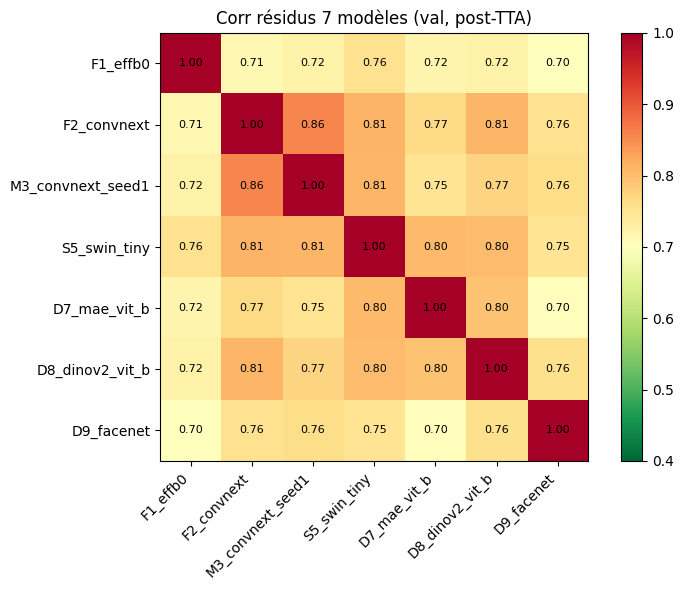


>>> 5 paires les moins corrélées :
D9_facenet    F1_effb0        0.698512
F1_effb0      D9_facenet      0.698512
D9_facenet    D7_mae_vit_b    0.703158
D7_mae_vit_b  D9_facenet      0.703158
F2_convnext   F1_effb0        0.711975
dtype: float64

>>> 5 paires les plus corrélées :
M3_convnext_seed1  M3_convnext_seed1   NaN
S5_swin_tiny       S5_swin_tiny        NaN
D7_mae_vit_b       D7_mae_vit_b        NaN
D8_dinov2_vit_b    D8_dinov2_vit_b     NaN
D9_facenet         D9_facenet          NaN
dtype: float64


In [10]:
target = df_val.set_index('filename').loc[FILENAMES, 'FaceOcclusion'].values
gender = df_val.set_index('filename').loc[FILENAMES, 'gender'].values
y = target

residuals = pd.DataFrame({n: PREDS[n] - target for n in PREDS})
corr = residuals.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr.values, vmin=0.4, vmax=1.0, cmap='RdYlGn_r')
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Corr résidus 7 modèles (val, post-TTA)')
plt.tight_layout(); plt.show()

print('\n>>> 5 paires les moins corrélées :')
c = corr.where(~np.eye(len(corr), dtype=bool)).stack().sort_values()
print(c.head(5))
print('\n>>> 5 paires les plus corrélées :')
print(c.tail(5))

## 8. Ensemble pondéré 7 modèles (SLSQP + 5-fold CV honnête)

In [ ]:
from scipy.optimize import minimize
from sklearn.model_selection import KFold

names = list(PREDS.keys())
P = np.stack([PREDS[n] for n in names])

def optimize_weights(P_arr, y_arr, g_arr, x0=None):
    M = P_arr.shape[0]
    if x0 is None: x0 = np.ones(M) / M
    cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1.0}]
    bnds = [(0.0, 1.0)] * M
    return minimize(
        lambda w: compute_score(pd.DataFrame({
            'pred': (w[:,None]*P_arr).sum(0), 'target': y_arr, 'gender': g_arr})
        )['score'],
        x0=x0, method='SLSQP', bounds=bnds, constraints=cons,
        options={'ftol': 1e-9, 'maxiter': 400},
    )


res_full = optimize_weights(P, y, gender)
w_full = res_full.x
print('=== Poids optimaux (val 100%) ===')
for n, w in zip(names, w_full):
    print(f'  {n:22s} : {w:.3f}')
print(f'Score full-val : {res_full.fun:.5f}')


w_uniform = np.ones(len(names)) / len(names)
p_uni = (w_uniform[:,None] * P).sum(0)
s_uni = compute_score(pd.DataFrame({'pred': p_uni, 'target': y, 'gender': gender}))['score']
print(f'Score uniforme (7) : {s_uni:.5f}')


kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred = np.full(len(y), np.nan)
oof_weights = []
for k, (tr, te) in enumerate(kf.split(np.arange(len(y)))):
    res_k = optimize_weights(P[:, tr], y[tr], gender[tr])
    oof_weights.append(res_k.x)
    oof_pred[te] = (res_k.x[:,None] * P[:, te]).sum(0)

oof_score_w = compute_score(pd.DataFrame({'pred': oof_pred, 'target': y, 'gender': gender}))
print(f'\n=== ENS_7weighted_5foldCV ===')
print(f'Score : {oof_score_w["score"]:.5f} | err_F {oof_score_w["err_F"]:.5f} | err_M {oof_score_w["err_M"]:.5f} | gap {oof_score_w["gap"]:.5f}')

w_mean = np.mean(oof_weights, axis=0)
w_std  = np.std(oof_weights, axis=0)
print(f'\nPoids moyens 5-fold (stabilité):')
for n, m, s in zip(names, w_mean, w_std):
    print(f'  {n:22s} : {m:.3f} ± {s:.3f}')

=== Poids optimaux (val 100%) ===
  F1_effb0               : 0.277
  F2_convnext            : 0.091
  M3_convnext_seed1      : 0.154
  S5_swin_tiny           : 0.238
  D7_mae_vit_b           : 0.000
  D8_dinov2_vit_b        : 0.036
  D9_facenet             : 0.203
Score full-val : 0.00097
Score uniforme (7) : 0.00099

=== ENS_7weighted_5foldCV ===
Score : 0.00102 | err_F 0.00042 | err_M 0.00082 | gap 0.00040

Poids moyens 5-fold (stabilité):
  F1_effb0               : 0.271 ± 0.035
  F2_convnext            : 0.085 ± 0.065
  M3_convnext_seed1      : 0.157 ± 0.049
  S5_swin_tiny           : 0.219 ± 0.072
  D7_mae_vit_b           : 0.007 ± 0.014
  D8_dinov2_vit_b        : 0.053 ± 0.029
  D9_facenet             : 0.208 ± 0.085


## 9. Stacking LightGBM enrichi (7 modèles)

Mêmes features que Phase B+ : 7 preds + gender + stats désaccord. Plus de modèles → plus de signal.

In [12]:
import lightgbm as lgb

def build_features(P_arr, gender_arr):
    M, N = P_arr.shape
    feats = {f'pred_{names[i]}': P_arr[i] for i in range(M)}
    feats['gender']   = gender_arr.astype(np.float32)
    feats['p_mean']   = P_arr.mean(axis=0)
    feats['p_std']    = P_arr.std(axis=0)
    feats['p_min']    = P_arr.min(axis=0)
    feats['p_max']    = P_arr.max(axis=0)
    feats['p_range']  = feats['p_max'] - feats['p_min']
    feats['p_median'] = np.median(P_arr, axis=0)
    return pd.DataFrame(feats)

X_full = build_features(P, gender)
print(f'Features shape : {X_full.shape}')

sample_w = (1.0/30.0 + y).astype(np.float32)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred_stk = np.full(len(y), np.nan)
gbms = []
for k, (tr, te) in enumerate(kf.split(np.arange(len(y)))):
    dtr = lgb.Dataset(X_full.iloc[tr], label=y[tr], weight=sample_w[tr])
    dte = lgb.Dataset(X_full.iloc[te], label=y[te], weight=sample_w[te], reference=dtr)
    params = dict(
        objective='regression', learning_rate=0.02,
        num_leaves=15, max_depth=4, min_data_in_leaf=200,
        feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=5,
        lambda_l2=1.0, verbose=-1, metric='mse',
    )
    gbm = lgb.train(params, dtr, num_boost_round=3000,
                    valid_sets=[dte],
                    callbacks=[lgb.early_stopping(80), lgb.log_evaluation(0)])
    pred_te = np.clip(gbm.predict(X_full.iloc[te], num_iteration=gbm.best_iteration), 0.0, 1.0)
    oof_pred_stk[te] = pred_te
    gbms.append(gbm)
    print(f'fold {k}: best_iter={gbm.best_iteration}')

oof_score_stk = compute_score(pd.DataFrame({'pred': oof_pred_stk, 'target': y, 'gender': gender}))
print(f'\n=== STACK_LGBM_7models 5-fold CV ===')
print(f'Score : {oof_score_stk["score"]:.5f} | err_F {oof_score_stk["err_F"]:.5f} | err_M {oof_score_stk["err_M"]:.5f} | gap {oof_score_stk["gap"]:.5f}')

imp = np.mean([g.feature_importance(importance_type='gain') for g in gbms], axis=0)
imp_df = pd.DataFrame({'feature': X_full.columns, 'gain': imp}).sort_values('gain', ascending=False)
print('\nTop features :')
print(imp_df.to_string(index=False))

Features shape : (9977, 14)
Training until validation scores don't improve for 80 rounds
Early stopping, best iteration is:
[450]	valid_0's l2: 0.000866982
fold 0: best_iter=450
Training until validation scores don't improve for 80 rounds
Early stopping, best iteration is:
[240]	valid_0's l2: 0.000541908
fold 1: best_iter=240
Training until validation scores don't improve for 80 rounds
Early stopping, best iteration is:
[255]	valid_0's l2: 0.000640247
fold 2: best_iter=255
Training until validation scores don't improve for 80 rounds
Early stopping, best iteration is:
[428]	valid_0's l2: 0.000599251
fold 3: best_iter=428
Training until validation scores don't improve for 80 rounds
Early stopping, best iteration is:
[405]	valid_0's l2: 0.000508642
fold 4: best_iter=405

=== STACK_LGBM_7models 5-fold CV ===
Score : 0.00099 | err_F 0.00043 | err_M 0.00080 | gap 0.00037

Top features :
               feature      gain
                p_mean 77.847603
                 p_max 47.155556
       

In [ ]:
np.savez(EXP_DIR / 'phaseC_oof.npz',
         oof_pred=oof_pred, oof_pred_stk=oof_pred_stk,
         w_full=w_full, w_mean=w_mean, w_std=w_std,
         y=y, gender=gender, names=np.array(names))
print(f'saved phaseC_oof.npz')

saved phaseC_oof.npz


## 11. Tableau de synthèse

In [15]:
rows = []

phaseA = pd.read_csv(EXP_DIR / 'step5_phaseA_recipes.csv').iloc[0].to_dict()
rows.append({'recipe': 'PhaseA (ENS_0.4F1+0.6F2)', 'score': phaseA['score'],
             'err_F': phaseA['err_F'], 'err_M': phaseA['err_M'], 'gap': phaseA['gap']})

phB = pd.read_csv(EXP_DIR / 'step6_phaseB_recipes.csv')
pb = phB[phB['recipe'] == 'ENS_4weighted_5foldCV_TTA'].iloc[0]
rows.append({'recipe': 'PhaseB (4mod weighted CV)', 'score': pb['score'],
             'err_F': pb['err_F'], 'err_M': pb['err_M'], 'gap': pb['gap']})

phBp = pd.read_csv(EXP_DIR / 'step7_phaseBplus_recipes.csv')
for r_name in ['ENS_6weighted_5foldCV_TTA', 'STACK_LGBM_5foldCV_TTA']:
    rr = phBp[phBp['recipe'] == r_name]
    if len(rr):
        d = rr.iloc[0]
        rows.append({'recipe': f'PhaseB+ {r_name.split("_")[0]} CV', 'score': d['score'],
                     'err_F': d['err_F'], 'err_M': d['err_M'], 'gap': d['gap']})
# blend phaseB+
rr = phBp[phBp['recipe'].str.startswith('BLEND_')]
if len(rr):
    d = rr.iloc[0]
    rows.append({'recipe': 'PhaseB+ blend CV', 'score': d['score'],
                 'err_F': d['err_F'], 'err_M': d['err_M'], 'gap': d['gap']})

# Solos TTA des 7 modèles Phase C
for n in names:
    s = compute_score(pd.DataFrame({'pred': PREDS[n], 'target': y, 'gender': gender}))
    rows.append({'recipe': f'{n}_TTA', **{k: s[k] for k in ['score','err_F','err_M','gap']}})

# Phase C ensembles
rows.append({'recipe': 'ENS_7uniform_TTA', 'score': s_uni,
             **{k: compute_score(pd.DataFrame({'pred': p_uni, 'target': y, 'gender': gender}))[k]
                for k in ['err_F','err_M','gap']}})
p_full = (w_full[:,None] * P).sum(0)
s_full = compute_score(pd.DataFrame({'pred': p_full, 'target': y, 'gender': gender}))
rows.append({'recipe': 'ENS_7weighted_full_TTA (optim.)',
             **{k: s_full[k] for k in ['score','err_F','err_M','gap']}})
rows.append({'recipe': 'ENS_7weighted_5foldCV_TTA',
             **{k: oof_score_w[k] for k in ['score','err_F','err_M','gap']}})
rows.append({'recipe': 'STACK_LGBM_7_5foldCV_TTA',
             **{k: oof_score_stk[k] for k in ['score','err_F','err_M','gap']}})
rows.append({'recipe': f'BLEND_a={best_a:.3f}_5foldCV_TTA',
             **{k: oof_score_blend[k] for k in ['score','err_F','err_M','gap']}})

df_phC = pd.DataFrame(rows).sort_values('score').reset_index(drop=True)
df_phC['gap_%'] = (df_phC['gap'] / df_phC['score'] * 100).round(1)
ref = phaseA['score']
df_phC['gain_vs_PhA'] = df_phC['score'] - ref
df_phC['gain_%'] = (-df_phC['gain_vs_PhA'] / ref * 100).round(2)
df_phC.to_csv(EXP_DIR / 'step8_phaseC_recipes.csv', index=False)
df_phC

,recipe,score,err_F,err_M,gap,gap_%,gain_vs_PhA,gain_%
0,ENS_7weighted_full_TTA (optim.),0.000973,0.000415,0.000787,0.000372,38.2,-0.000056,5.43
1,BLEND_a=0.725_5foldCV_TTA,0.000983,0.000407,0.000791,0.000384,39.1,-0.000046,4.46
2,STACK_LGBM_7_5foldCV_TTA,0.000987,0.000427,0.000800,0.000374,37.8,-0.000042,4.05
3,ENS_7uniform_TTA,0.000994,0.000386,0.000791,0.000405,40.8,-0.000035,3.38
4,PhaseB+ blend CV,0.001000,0.000415,0.000805,0.000390,39.0,-0.000028,2.77
5,PhaseB+ ENS CV,0.001009,0.000434,0.000817,0.000383,38.0,-0.000020,1.93
6,PhaseB+ STACK CV,0.001016,0.000447,0.000826,0.000380,37.4,-0.000013,1.23
7,ENS_7weighted_5foldCV_TTA,0.001016,0.000416,0.000816,0.000400,39.4,-0.000013,1.22
8,PhaseA (ENS_0.4F1+0.6F2),0.001029,0.000435,0.000831,0.000396,38.5,0.000000,-0.00
9,PhaseB (4mod weighted CV),0.001032,0.000429,0.000831,0.000402,38.9,0.000004,-0.35


## 12. Sauvegarde pipeline final Phase C

In [17]:
w_final = w_mean / w_mean.sum()
print('Poids ensemble pondéré finaux :')
for n, w in zip(names, w_final):
    print(f'  {n:22s} : {w:.4f}')

ckpt_map = {
    'F1_effb0':           {'kind': 'timm', 'backbone': 'efficientnet_b0',
                            'ckpt': 'exp_F1_effb0.pt', 'kwargs': {}},
    'F2_convnext':        {'kind': 'timm', 'backbone': 'convnext_tiny',
                            'ckpt': 'exp_F2_convnext.pt', 'kwargs': {}},
    'M3_convnext_seed1':  {'kind': 'timm', 'backbone': 'convnext_tiny',
                            'ckpt': 'exp_M3_convnext_seed1.pt', 'kwargs': {}},
    'S5_swin_tiny':       {'kind': 'timm', 'backbone': 'swin_tiny_patch4_window7_224',
                            'ckpt': 'exp_S5_swin_tiny.pt', 'kwargs': {}},
    'D7_mae_vit_b':       {'kind': 'timm', 'backbone': 'vit_base_patch16_224.mae',
                            'ckpt': 'exp_D7_mae_vit_b.pt', 'kwargs': {}},
    'D8_dinov2_vit_b':    {'kind': 'timm', 'backbone': 'vit_base_patch14_dinov2.lvd142m',
                            'ckpt': 'exp_D8_dinov2_vit_b.pt', 'kwargs': {'img_size': 224}},
    'D9_facenet':         {'kind': 'facenet', 'backbone': 'InceptionResnetV1.vggface2',
                            'ckpt': 'exp_D9_facenet.pt', 'kwargs': {}},
}

pipeline = {
    'phase': 'C',
    'use_tta': True,
    'use_calib': False,
    'model_names': names,
    'models': [
        {'name': n, **ckpt_map[n], 'ckpt_path': str(ARTIFACTS_DIR / ckpt_map[n]['ckpt']),
         'weight': float(w_final[i])}
        for i, n in enumerate(names)
    ],
    'stacking': {
        'feature_columns': list(X_full.columns),
        'boosters_files': [],
        'n_folds': len(gbms),
    },
    'blend_alpha': float(best_a),
    'val_score_5foldCV_weighted': oof_score_w,
    'val_score_5foldCV_stacking': oof_score_stk,
    'val_score_5foldCV_blend':    oof_score_blend,
    'note': 'Phase C: 7 modèles (4 anciens + MAE + DINOv2 + FaceNet) + LGBM stacking + blend',
}

stk_dir = ARTIFACTS_DIR / 'lgbm_phaseC'
stk_dir.mkdir(exist_ok=True)
for k, gbm in enumerate(gbms):
    p = stk_dir / f'fold{k}.txt'
    gbm.save_model(str(p), num_iteration=gbm.best_iteration)
    pipeline['stacking']['boosters_files'].append(str(p))

pipeline_path = ARTIFACTS_DIR / 'pipeline_phaseC.pkl'
with open(pipeline_path, 'wb') as f:
    pickle.dump(pipeline, f)
print(f'\npipeline saved -> {pipeline_path}')

p_val_final = best_a * oof_pred_stk + (1 - best_a) * oof_pred
pd.DataFrame({'filename': FILENAMES, 'pred': p_val_final, 'target': y, 'gender': gender}).to_csv(
    EXP_DIR / 'preds_val_pipelineC.csv', index=False)

print(f"""
========== RÉCAP PHASE C (5-fold CV honnête) ==========
PhaseA best        : {phaseA['score']:.5f}
PhaseB best (CV)   : {pb['score']:.5f}
Phase B+ blend     : {phBp[phBp['recipe'].str.startswith('BLEND_')].iloc[0]['score']:.5f}
Phase C weighted   : {oof_score_w['score']:.5f}
Phase C stacking   : {oof_score_stk['score']:.5f}
Phase C blend      : {oof_score_blend['score']:.5f}  <-- final
Cible leaderboard  : 0.00092

>>> Gain vs PhaseA : {(phaseA['score'] - oof_score_blend['score']) / phaseA['score'] * 100:+.1f} %
""")

Poids ensemble pondéré finaux :
  F1_effb0               : 0.2712
  F2_convnext            : 0.0853
  M3_convnext_seed1      : 0.1569
  S5_swin_tiny           : 0.2188
  D7_mae_vit_b           : 0.0071
  D8_dinov2_vit_b        : 0.0531
  D9_facenet             : 0.2075

pipeline saved -> <repo>/artifacts/pipeline_phaseC.pkl

========== RÉCAP PHASE C (5-fold CV honnête) ==========
PhaseA best        : 0.00103
PhaseB best (CV)   : 0.00103
Phase B+ blend     : 0.00100
Phase C weighted   : 0.00102
Phase C stacking   : 0.00099
Phase C blend      : 0.00098  <-- final
Cible leaderboard  : 0.00092

>>> Gain vs PhaseA : +4.5 %

